In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy.optimize import brentq
from scipy.stats import norm

# Mini-Project 3 (Part 2): CDO valuation with the Lintner model

FRE 6103 Valuation for Financial Engineering (NYU Tandon) | Raj Pawar (rsp9234) and Michael Brick (mb11311)

We value Class A, Class B and the bank's residual with the Lintner model from class (Lecture 6), on the
same 1000 cases of correlated defaults as Part 1. The steps follow the assignment:

1. scheduled cash flows and the waterfall for the new classes,
2. 1000 simulations from the static (moment-matched) random numbers,
3. the PV of each tranche in each case at the risk-free rate, the covariance matrix and a default indicator,
4. the implicit cost of risk from the bonds' market value, and the cost per unit risk,
5. the Lintner values,

and then the bonus: the structure that gives the residual the most value with Class A held at $15 MM.

## 1. Inputs

The classes are the ones given for Part 2. We use the target rates as the coupons, so a class sold
at par pays its target rate. All amounts are in $ millions.

In [2]:
N_CASES = 1000
SEED = 6103                   # for the fixed random numbers (same as Part 1)

base = {
    "n_bonds": 10,
    "years": 5,
    "freq": 4,                # payments per year
    "face": 10.0,             # $MM per bond
    "coupon": 0.06,           # annual, paid quarterly
    "pd": 0.04,               # annual default probability (pi)
    "lgd": 0.6,               # loss given default (lambda)
    "rho": 0.2,               # "correlation" between any two bonds' default dates
    "a_notional": 15.0,       # Class A principal ($MM)
    "a_coupon": 0.045,        # Class A target rate, used as its coupon
    "b_notional": 30.0,       # Class B principal ($MM)
    "b_coupon": 0.055,        # Class B target rate, used as its coupon
}

RISK_FREE = 0.04              # p.a., compounded quarterly
MARKET_YTM = 0.09             # market yield on the bonds

N_BONDS = base["n_bonds"]
FREQ = base["freq"]
N_PERIODS = base["years"] * base["freq"]      # 20 quarters
quarters = np.arange(1, N_PERIODS + 1)

## 2. The Part 1 model

These are the Part 1 functions, unchanged: the BIS bond cash flows, the fixed random numbers and
their moment matching, the correlated default times and the waterfall.

In [3]:
def promised_cash_flows(face, coupon, n_periods, freq):
    """Coupon every period and the face value with the last coupon."""
    cf = np.full(n_periods, face * coupon / freq)
    cf[-1] += face
    return cf


def bis_cash_flows(promised, default_period, lgd):
    """Cash flows of bonds given the period in which each one defaults.

    BIS model: (1 - lgd) of every promised payment is always paid and the other
    lgd stops in the period of default. default_period can be any shape; the
    result has one more axis for the periods. A default_period beyond the last
    period means the bond never defaults.
    """
    periods = np.arange(1, len(promised) + 1)
    default_period = np.asarray(default_period)[..., None]
    paid_share = np.where(periods >= default_period, 1.0 - lgd, 1.0)
    return promised * paid_share


def load_fixed_normals(path, n_cases, n_bonds, seed):
    """Read the fixed random numbers, creating the file from the seed if it is missing.

    Returns (table, source). The values are always the ones stored in the file,
    so every run uses exactly the same numbers. Cases are numbered from 1.
    """
    path = Path(path)
    if path.exists():
        source = "read from file"
    else:
        rng = np.random.default_rng(seed)
        columns = [f"Bond {i}" for i in range(1, n_bonds + 1)]
        index = pd.RangeIndex(1, n_cases + 1, name="case")
        draws = pd.DataFrame(rng.standard_normal((n_cases, n_bonds)), columns=columns, index=index)
        path.parent.mkdir(parents=True, exist_ok=True)
        draws.to_csv(path, float_format="%.10f")
        source = f"generated with seed {seed}"
    table = pd.read_csv(path, index_col="case")
    if table.shape != (n_cases, n_bonds):
        raise ValueError(f"{path} has shape {table.shape}, expected {(n_cases, n_bonds)}")
    if not np.isfinite(table.values).all():
        raise ValueError(f"{path} contains values that are not finite numbers")
    return table, source


def moment_match(Z):
    """De-mean the draws and rescale them so the sample has exactly the moments of independent standard normals.

    As shown in class: subtract each column's mean, take the population covariance of the draws and
    multiply the de-meaned draws by the inverse of its Cholesky factor. Afterwards every bond's
    numbers have mean 0 and variance 1 across the cases, and no two bonds' numbers are correlated.
    """
    Z = np.asarray(Z, dtype=float)
    if Z.ndim != 2 or Z.shape[0] <= Z.shape[1]:
        raise ValueError(f"moment matching needs a cases x bonds table with more cases than bonds, got shape {Z.shape}")
    if not np.isfinite(Z).all():
        raise ValueError("moment matching needs finite numbers")
    demeaned = Z - Z.mean(axis=0)
    covariance = demeaned.T @ demeaned / len(Z)
    try:
        chol = np.linalg.cholesky(covariance)
    except np.linalg.LinAlgError as error:
        raise ValueError("moment matching needs columns that are not copies or combinations of each other") from error
    return np.linalg.solve(chol, demeaned.T).T      # same as demeaned @ inverse(chol).T


def correlation_matrix(n, rho):
    """n x n matrix with 1 on the diagonal and rho everywhere else."""
    corr = np.full((n, n), float(rho))
    np.fill_diagonal(corr, 1.0)
    return corr


def correlate(Z, rho):
    """Turn independent normals (cases x bonds) into normals with pairwise correlation rho."""
    chol = np.linalg.cholesky(correlation_matrix(Z.shape[1], rho))
    return Z @ chol.T


def default_times(Z, pd_annual, rho):
    """Default time in years for every case and bond.

    u = N(x) for the correlated normals x, then t = ln(1 - u) / ln(1 - pi) as in
    Lecture 5. With pi = 0 nothing ever defaults.
    """
    if pd_annual == 0:
        return np.full(Z.shape, np.inf)
    U = norm.cdf(correlate(Z, rho))
    with np.errstate(divide="ignore"):
        return np.log(1.0 - U) / np.log(1.0 - pd_annual)


def default_period(T, freq, n_periods):
    """Period in which default happens (1, 2, ...). n_periods + 1 means the bond survives."""
    period = np.ceil(np.minimum(np.asarray(T, dtype=float) * freq, n_periods + 1))
    return np.maximum(period, 1).astype(int)


def waterfall(pool_cf, a_due, b_due):
    """Split pool cash flows (cases x periods) between Class A, Class B and equity.

    Each period stands alone: Class A is paid first up to what it is due, then
    Class B, and the residual goes to equity. No carry-forwards, so a shortfall
    is not made up later and nothing is held back.
    """
    a_paid = np.minimum(pool_cf, a_due)
    b_paid = np.minimum(pool_cf - a_paid, b_due)
    equity = pool_cf - a_paid - b_paid
    return {"A": a_paid, "B": b_paid, "Equity": equity}


def validate_deal(p):
    """Raise ValueError if an input is outside the range the model can handle."""
    if not 0.0 <= p["pd"] < 1.0:
        raise ValueError(f"annual default probability must be in [0, 1), got {p['pd']}")
    if not 0.0 <= p["lgd"] <= 1.0:
        raise ValueError(f"LGD must be in [0, 1], got {p['lgd']}")
    if not 0.0 <= p["rho"] < 1.0:
        raise ValueError(f"correlation must be in [0, 1), got {p['rho']}")
    for key in ("face", "coupon", "a_notional", "a_coupon", "b_notional", "b_coupon"):
        if not p[key] >= 0:
            raise ValueError(f"{key} must be a number that is not negative, got {p[key]}")


def simulate(Z, p):
    """Run the whole model for the parameter set p on the independent normals Z (cases x bonds)."""
    validate_deal(p)
    if Z.ndim != 2 or Z.shape[1] != p["n_bonds"]:
        raise ValueError(f"random numbers must be a cases x {p['n_bonds']} table, got shape {Z.shape}")
    if not np.isfinite(Z).all():
        raise ValueError("random numbers contain values that are not finite")
    n_periods = p["years"] * p["freq"]
    bond_promised = promised_cash_flows(p["face"], p["coupon"], n_periods, p["freq"])
    T = default_times(Z, p["pd"], p["rho"])
    Q = default_period(T, p["freq"], n_periods)
    bond_cf = bis_cash_flows(bond_promised, Q, p["lgd"])
    pool_cf = bond_cf.sum(axis=1)
    a_due = promised_cash_flows(p["a_notional"], p["a_coupon"], n_periods, p["freq"])
    b_due = promised_cash_flows(p["b_notional"], p["b_coupon"], n_periods, p["freq"])
    paid = waterfall(pool_cf, a_due, b_due)
    return {
        "T": T,
        "Q": Q,
        "defaulted": Q <= n_periods,
        "bond_promised": bond_promised,
        "pool_promised": p["n_bonds"] * bond_promised,
        "bond_cf": bond_cf,
        "pool_cf": pool_cf,
        "a_due": a_due,
        "b_due": b_due,
        "a_cf": paid["A"],
        "b_cf": paid["B"],
        "eq_cf": paid["Equity"],
    }

## 3. Step 1: scheduled cash flows of the classes

Each class gets its coupon every quarter and its principal back in quarter 20. If no bond defaults the residual
gets the rest. Each quarter stands alone: a shortfall is not made up later.

In [4]:
a_due = promised_cash_flows(base["a_notional"], base["a_coupon"], N_PERIODS, FREQ)
b_due = promised_cash_flows(base["b_notional"], base["b_coupon"], N_PERIODS, FREQ)
pool_due = N_BONDS * promised_cash_flows(base["face"], base["coupon"], N_PERIODS, FREQ)
schedule = pd.DataFrame({"pool promised": pool_due, "due to Class A": a_due, "due to Class B": b_due,
                         "residual if no default": pool_due - a_due - b_due}, index=pd.Index(quarters, name="quarter"))
schedule.loc["Total"] = schedule.sum()
schedule.round(5)

,pool promised,due to Class A,due to Class B,residual if no default
quarter,,,,
1,1.5,0.16875,0.4125,0.91875
2,1.5,0.16875,0.4125,0.91875
3,1.5,0.16875,0.4125,0.91875
4,1.5,0.16875,0.4125,0.91875
5,1.5,0.16875,0.4125,0.91875
6,1.5,0.16875,0.4125,0.91875
7,1.5,0.16875,0.4125,0.91875
8,1.5,0.16875,0.4125,0.91875
9,1.5,0.16875,0.4125,0.91875


## 4. Step 2: 1000 simulations from the static random numbers

The same file of normals as Part 1, moment matched as shown in class, so the default dates and the
pool's cash flows are the Part 1 ones. Only the split between the classes changes.

In [5]:
candidates = [Path("fixed_random_numbers.csv"), Path("../data/fixed_random_numbers.csv")]
random_file = next((f for f in candidates if f.exists()), candidates[0])
z_table, source = load_fixed_normals(random_file, N_CASES, N_BONDS, SEED)
Z = moment_match(z_table.values)
sim = simulate(Z, base)
pool_cf = sim["pool_cf"]
print(f"{Z.shape[0]} cases x {Z.shape[1]} bonds ({source}), moment matched")
print(f"Average number of defaults per case: {sim['defaulted'].sum(axis=1).mean():.3f}")

1000 cases x 10 bonds (read from file), moment matched
Average number of defaults per case: 1.821


## 5. Step 3: PVs at the risk-free rate, covariance matrix and default indicators

In each case every tranche's 20 quarterly cash flows are discounted at the risk-free rate. The
default indicator is 1 when a class is paid less than it is due in some quarter.

In [6]:
def discount_factors(rate, freq, n_periods):
    """Factors that bring a payment at the end of quarter k = 1..n_periods back to today."""
    return (1.0 + rate / freq) ** -np.arange(1, n_periods + 1)


def tranche_cash_flows(pool_cf, p):
    """Class A, Class B and residual cash flows (cases x quarters) for the structure in p."""
    n_periods = pool_cf.shape[1]
    a_due = promised_cash_flows(p["a_notional"], p["a_coupon"], n_periods, p["freq"])
    b_due = promised_cash_flows(p["b_notional"], p["b_coupon"], n_periods, p["freq"])
    paid = waterfall(pool_cf, a_due, b_due)
    return {"A": paid["A"], "B": paid["B"], "Residual": paid["Equity"], "a_due": a_due, "b_due": b_due}


def tranche_pvs(flows, rate, freq):
    """PV at the risk-free rate of each tranche in each case: a cases x 3 table (A, B, residual)."""
    factors = discount_factors(rate, freq, flows["A"].shape[1])
    return np.column_stack([flows[name] @ factors for name in ("A", "B", "Residual")])


def default_indicators(flows, tol=1e-09):
    """1 where a class is paid less than it is due in some quarter, else 0 (cases x 2: A, B)."""
    short_a = (flows["A"] < flows["a_due"] - tol).any(axis=1)
    short_b = (flows["B"] < flows["b_due"] - tol).any(axis=1)
    return np.column_stack([short_a, short_b]).astype(int)


flows = tranche_cash_flows(pool_cf, base)
pv = tranche_pvs(flows, RISK_FREE, FREQ)
defaults = default_indicators(flows)
names = ["Class A", "Class B", "Residual"]
pv_table = pd.DataFrame(pv, columns=names, index=pd.Index(np.arange(1, N_CASES + 1), name="case"))
pv_table["Pool"] = pv_table.sum(axis=1)
pv_table["Class A default"] = defaults[:, 0]
pv_table["Class B default"] = defaults[:, 1]
print("Cases in which each class is short:", dict(zip(["Class A", "Class B"], defaults.sum(axis=0))))
pv_table.head(10).round(4)

Cases in which each class is short: {'Class A': 0, 'Class B': 0}


,Class A,Class B,Residual,Pool,Class A default,Class B default
case,,,,,,
1,15.3384,32.0301,61.6543,109.0228,0,0
2,15.3384,32.0301,61.6543,109.0228,0,0
3,15.3384,32.0301,61.6543,109.0228,0,0
4,15.3384,32.0301,50.2562,97.6247,0,0
5,15.3384,32.0301,27.0399,74.4084,0,0
6,15.3384,32.0301,45.8497,93.2182,0,0
7,15.3384,32.0301,61.6543,109.0228,0,0
8,15.3384,32.0301,56.2050,103.5734,0,0
9,15.3384,32.0301,50.9743,98.3428,0,0


In [7]:
covariance = pd.DataFrame(np.cov(pv, rowvar=False), index=names, columns=names)
covariance.round(4)

,Class A,Class B,Residual
Class A,0.0,0.0,-0.0000
Class B,0.0,0.0,-0.0000
Residual,-0.0,-0.0,99.4309


## 6. Step 4: the implicit cost of risk

The bonds' market value is the pool's promised cash flows at the 9% market yield. The pool's expected
PV at the risk-free rate is higher; the gap is what the market charges for the risk. Dividing by the
variance of the pool's PV gives the cost per unit risk (Lecture 6, slide 44).

In [8]:
def bond_market_value(p, ytm):
    """Market value of the bonds: the pool's promised cash flows discounted at the market yield."""
    n_periods = p["years"] * p["freq"]
    promised = p["n_bonds"] * promised_cash_flows(p["face"], p["coupon"], n_periods, p["freq"])
    return float(promised @ discount_factors(ytm, p["freq"], n_periods))


def cost_of_risk(pool_pv, market_value):
    """The bonds' implicit cost of risk and the cost per unit of risk (variance), Lecture 6 slide 44."""
    expected = float(pool_pv.mean())
    variance = float(pool_pv.var(ddof=1))
    if not variance > 0:
        raise ValueError("the pool's PV is the same in every case, so there is no risk to price")
    cost = expected - market_value
    return {"market_value": market_value, "expected_pool_pv": expected, "cost_of_risk": cost,
            "pool_variance": variance, "cost_per_unit_risk": cost / variance}


risk = cost_of_risk(pv.sum(axis=1), bond_market_value(base, MARKET_YTM))
for key, value in risk.items():
    print(f"{key:20} {value:12.6f}")

market_value            88.027216
expected_pool_pv        98.500745
cost_of_risk            10.473529
pool_variance           99.430902
cost_per_unit_risk       0.105335


## 7. Step 5: Lintner values

Each tranche's value is its expected PV less the cost per unit risk times the covariance of its PV
with the pool's PV. The three covariances add up to the pool's variance, so the three values add up
to the bonds' market value.

In [9]:
def lintner_values(pv, cost_per_unit_risk):
    """Value of each tranche: expected PV less the cost per unit risk times its covariance with the pool."""
    covariance = np.cov(pv, rowvar=False, ddof=1)
    cov_with_pool = covariance.sum(axis=1)
    expected = pv.mean(axis=0)
    charge = cost_per_unit_risk * cov_with_pool
    return {"expected_pv": expected, "covariance": covariance, "cov_with_pool": cov_with_pool,
            "risk_charge": charge, "value": expected - charge}


def value_cdo(pool_cf, p, rate, ytm):
    """All the Part 2 steps for one structure: PVs, default indicators, cost of risk, Lintner values."""
    flows = tranche_cash_flows(pool_cf, p)
    pv = tranche_pvs(flows, rate, p["freq"])
    risk = cost_of_risk(pv.sum(axis=1), bond_market_value(p, ytm))
    return {"pv": pv, "defaults": default_indicators(flows), **risk,
            **lintner_values(pv, risk["cost_per_unit_risk"])}


v = value_cdo(pool_cf, base, RISK_FREE, MARKET_YTM)
values = pd.DataFrame({
    "principal": [base["a_notional"], base["b_notional"], np.nan],
    "expected PV": v["expected_pv"],
    "covariance with pool": v["cov_with_pool"],
    "risk charge": v["risk_charge"],
    "Lintner value": v["value"],
}, index=names)
values.loc["Total"] = values.sum()
print(f"Total of the values {v['value'].sum():.6f} vs bonds' market value {v['market_value']:.6f}")
values.round(4)

Total of the values 88.027216 vs bonds' market value 88.027216


,principal,expected PV,covariance with pool,risk charge,Lintner value
Class A,15.0,15.3384,0.0000,0.0000,15.3384
Class B,30.0,32.0301,0.0000,0.0000,32.0301
Residual,NaN,51.1323,99.4309,10.4735,40.6587
Total,45.0,98.5007,99.4309,10.4735,88.0272


Neither class is ever short, so their PVs are the same in every case: no covariance with the pool, no
risk charge, and each is worth its promised cash flows at 4%. That is more than par, because their
coupons are above 4%. The coupon at which each class is worth exactly its principal:

In [10]:
def structure_values(pool_cf, p, rate, cost_per_unit_risk):
    """Lintner values and default probabilities for another structure on the same pool.

    The cost per unit risk comes from the bonds alone, so it stays the same whatever the
    classes look like. Only each tranche's covariance with the pool has to be recomputed.
    """
    flows = tranche_cash_flows(pool_cf, p)
    pv = tranche_pvs(flows, rate, p["freq"])
    pool = pv.sum(axis=1)
    cov_with_pool = (pv - pv.mean(axis=0)).T @ (pool - pool.mean()) / (len(pool) - 1)
    return {"value": pv.mean(axis=0) - cost_per_unit_risk * cov_with_pool,
            "p_default": default_indicators(flows).mean(axis=0)}


def fair_coupon(pool_cf, p, rate, cost_per_unit_risk, cls='b', coupons=None):
    """Lowest coupon at which Class A or B is worth its principal, or None if no coupon up to 100% does it.

    A class that is too large stays below par whatever its coupon. The value is not always rising
    in the coupon (the Lintner weights of the no-default cases are negative), so the coupons are
    scanned upwards (0% to 100% in 1% steps unless coupons are given) to find the first one that
    reaches par before the root is refined.
    """
    if coupons is None:
        coupons = np.linspace(0.0, 1.0, 101)
    if cls not in ("a", "b"):
        raise ValueError(f"class must be 'a' or 'b', got {cls!r}")
    principal = p[f"{cls}_notional"]
    if not principal > 0:
        raise ValueError(f"Class {cls.upper()} has no principal to price")
    column = 0 if cls == "a" else 1

    def gap(coupon):
        return structure_values(pool_cf, {**p, f"{cls}_coupon": coupon}, rate, cost_per_unit_risk)["value"][column] - principal

    previous = None
    for coupon in coupons:
        if gap(coupon) >= 0:
            return float(coupon) if previous is None else brentq(gap, previous, coupon, xtol=1e-12)
        previous = coupon
    return None


lam = v["cost_per_unit_risk"]
fair = {cls: fair_coupon(pool_cf, base, RISK_FREE, lam, cls) for cls in ("a", "b")}
at_fair = value_cdo(pool_cf, {**base, "a_coupon": fair["a"], "b_coupon": fair["b"]}, RISK_FREE, MARKET_YTM)
print(f"Fair coupons: Class A {fair['a']:.4%}, Class B {fair['b']:.4%}")
print(f"Values at those coupons: {np.round(at_fair['value'], 4)}")
print(f"Bank's gain at the target rates: {base['a_notional'] + base['b_notional'] + v['value'][2] - v['market_value']:.4f}")

Fair coupons: Class A 4.0000%, Class B 4.0000%
Values at those coupons: [15.     30.     43.0272]
Bank's gain at the target rates: -2.3685


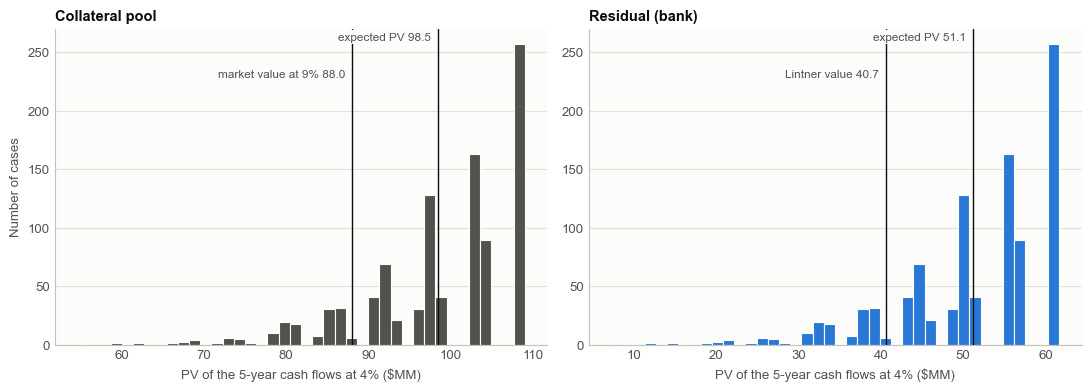

In [11]:
# One colour per entity in every chart.
COLORS = {'surface': '#fcfcfb',
 'ink': '#0b0b0b',
 'ink_secondary': '#52514e',
 'grid': '#e1e0d9',
 'axis': '#c3c2b7',
 'pool': '#52514e',
 'benchmark': '#898781',
 'equity': '#2a78d6',
 'class_a': '#eb6834',
 'class_b': '#1baf7a'}


def apply_chart_style():
    """Quiet chart defaults: thin marks, a hairline grid and no box around the plot."""
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9.5,
        "figure.facecolor": "white",
        "axes.facecolor": COLORS["surface"],
        "axes.edgecolor": COLORS["axis"],
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": COLORS["grid"],
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "axes.labelcolor": COLORS["ink_secondary"],
        "axes.titlecolor": COLORS["ink"],
        "axes.titlesize": 10.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "xtick.color": COLORS["ink_secondary"],
        "ytick.color": COLORS["ink_secondary"],
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "lines.linewidth": 2.0,
        "lines.solid_capstyle": "round",
        "savefig.dpi": 160,
        "savefig.bbox": "tight",
    })


def reference_line(ax, x, text, height):
    """Vertical hairline with its label written beside it, so it needs no legend entry."""
    ax.axvline(x, color=COLORS["ink"], linewidth=1.0)
    ax.annotate(text, xy=(x, height), xycoords=("data", "axes fraction"), xytext=(-5, 0),
                textcoords="offset points", ha="right", va="top", fontsize=8.5, color=COLORS["ink_secondary"])


def plot_pv_distributions(pool_pv, residual_pv, market_value, residual_value, rate):
    """PV at the risk-free rate across the cases: the collateral pool (left) and the residual (right)."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    panels = [
        (axes[0], pool_pv, COLORS["pool"], "Collateral pool", (market_value, "market value at 9%")),
        (axes[1], residual_pv, COLORS["equity"], "Residual (bank)", (residual_value, "Lintner value")),
    ]
    label_box = {"boxstyle": "square,pad=0.15", "fc": COLORS["surface"], "ec": "none"}
    for ax, x, color, title, (mark, mark_label) in panels:
        ax.hist(x, bins=40, color=color, edgecolor=COLORS["surface"], linewidth=0.8)
        for value, text, height in ((x.mean(), f"expected PV {x.mean():.1f}", 0.99), (mark, f"{mark_label} {mark:.1f}", 0.87)):
            ax.axvline(value, color=COLORS["ink"], linewidth=1.0)
            ax.annotate(text, xy=(value, height), xycoords=("data", "axes fraction"), xytext=(-5, 0), textcoords="offset points",
                        ha="right", va="top", fontsize=8.5, color=COLORS["ink_secondary"], bbox=label_box, zorder=5)
        ax.set_title(title)
        ax.set_xlabel(f"PV of the 5-year cash flows at {rate:.0%} ($MM)")
    axes[0].set_ylabel("Number of cases")
    fig.tight_layout()
    return fig


apply_chart_style()
plot_pv_distributions(pv.sum(axis=1), pv[:, 2], v["market_value"], v["value"][2], RISK_FREE)
plt.show()

## 8. What moves the values

One input of the default model at a time, with the bonds' market value held at its 9% price. Then the
same valuation on 500 fresh sets of 1000 cases, as drawn and moment matched, to see how much the numbers
move from one set of random numbers to another.

In [12]:
def value_sensitivity(Z, p, rate, ytm, name, values):
    """Re-value the structure with one model input changed. The bonds' market value stays at its
    price at the market yield, so the cost of risk moves with the model's expected cash flows."""
    rows = []
    for x in values:
        q = {**p, name: x}
        v = value_cdo(simulate(Z, q)["pool_cf"], q, rate, ytm)
        rows.append({name: x, "expected_pool_pv": v["expected_pool_pv"], "cost_of_risk": v["cost_of_risk"],
                     "cost_per_unit_risk": v["cost_per_unit_risk"], "value_a": float(v["value"][0]),
                     "value_b": float(v["value"][1]), "value_residual": float(v["value"][2]),
                     "p_default_a": float(v["defaults"][:, 0].mean()), "p_default_b": float(v["defaults"][:, 1].mean())})
    return rows


for name, grid in {"rho": (0.0, 0.2, 0.4, 0.6, 0.8), "pd": (0.02, 0.04, 0.06, 0.08, 0.12),
                   "lgd": (0.4, 0.6, 0.8, 1.0)}.items():
    display(pd.DataFrame(value_sensitivity(Z, base, RISK_FREE, MARKET_YTM, name, grid)).set_index(name).round(4))

,expected_pool_pv,cost_of_risk,cost_per_unit_risk,value_a,value_b,value_residual,p_default_a,p_default_b
rho,,,,,,,,
0.0,98.4529,10.4257,0.1984,15.3384,32.0301,40.6587,0.0,0.000
0.2,98.5007,10.4735,0.1053,15.3384,32.0301,40.6587,0.0,0.000
0.4,98.3977,10.3705,0.0638,15.3384,31.9785,40.7103,0.0,0.003
0.6,98.5377,10.5105,0.0472,15.3384,31.8471,40.8418,0.0,0.013
0.8,98.7232,10.6960,0.0343,15.3384,31.4786,41.2103,0.0,0.049


,expected_pool_pv,cost_of_risk,cost_per_unit_risk,value_a,value_b,value_residual,p_default_a,p_default_b
pd,,,,,,,,
0.02,103.4824,15.4552,0.3076,15.3384,32.0301,40.6587,0.0,0.000
0.04,98.5007,10.4735,0.1053,15.3384,32.0301,40.6587,0.0,0.000
0.06,93.7244,5.6972,0.0408,15.3384,32.0301,40.6587,0.0,0.000
0.08,89.1762,1.1490,0.0069,15.3384,32.0198,40.6691,0.0,0.002
0.12,81.4621,-6.5651,-0.0347,15.3384,32.0381,40.6508,0.0,0.014


,expected_pool_pv,cost_of_risk,cost_per_unit_risk,value_a,value_b,value_residual,p_default_a,p_default_b
lgd,,,,,,,,
0.4,102.0081,13.9809,0.3164,15.3384,32.0301,40.6587,0.000,0.000
0.6,98.5007,10.4735,0.1053,15.3384,32.0301,40.6587,0.000,0.000
0.8,94.9934,6.9662,0.0394,15.3384,31.8494,40.8394,0.000,0.017
1.0,91.4861,3.4588,0.0125,15.3304,31.4521,41.2447,0.001,0.033


In [13]:
def valuation_precision(p, rate, ytm, n_cases, n_sets=500, seed=6105):
    """How much the Lintner values move from one set of random numbers to another.

    Draws n_sets fresh tables of n_cases x n_bonds normals and values the structure on each,
    once as drawn and once after moment matching.
    """
    rng = np.random.default_rng(seed)
    as_drawn, matched = [], []
    for _ in range(n_sets):
        Z = rng.standard_normal((n_cases, p["n_bonds"]))
        for store, table in ((as_drawn, Z), (matched, moment_match(Z))):
            v = value_cdo(simulate(table, p)["pool_cf"], p, rate, ytm)
            store.append(list(v["value"]) + [v["cost_per_unit_risk"], v["expected_pool_pv"], v["expected_pv"][2]])
    as_drawn, matched = np.array(as_drawn), np.array(matched)
    return {"n_sets": n_sets, "seed": seed,
            "columns": ["value_a", "value_b", "value_residual", "cost_per_unit_risk", "expected_pool_pv",
                        "expected_pv_residual"],
            "sd_as_drawn": as_drawn.std(axis=0, ddof=1).tolist(), "sd_matched": matched.std(axis=0, ddof=1).tolist(),
            "mean_as_drawn": as_drawn.mean(axis=0).tolist(), "mean_matched": matched.mean(axis=0).tolist()}


precision = valuation_precision(base, RISK_FREE, MARKET_YTM, N_CASES, n_sets=500)
pd.DataFrame({"sd as drawn": precision["sd_as_drawn"], "sd moment matched": precision["sd_matched"]},
             index=precision["columns"]).round(4)

,sd as drawn,sd moment matched
value_a,0.0000,0.0000
value_b,0.0104,0.0097
value_residual,0.0104,0.0097
cost_per_unit_risk,0.0089,0.0041
expected_pool_pv,0.3328,0.1207
expected_pv_residual,0.3327,0.1206


## 9. Bonus: choosing Class B with Class A held at $15 MM

We search Class B's principal ($0 to $100 MM) and coupon (0% to 10%) and re-value each structure on the
same cases. The cost per unit risk comes from the bonds alone, so it stays fixed. We report the literal
answer (the residual's highest value), the bank's gain (cash from selling both classes at par plus the
residual, less the bonds) at Class B's target rate, Class B's fair coupon at each size, and the best size
at the target rate if Class B's default probability is capped.

In [14]:
def break_even_size(pool_cf, p, rate, cost_per_unit_risk, sizes):
    """Largest Class B principal at which its coupon in p is still worth par (value = principal).

    Below this size the coupon pays Class B more than its risk needs; above it Class B is
    worth less than par. Returns None if Class B is worth at least par at every size given.
    """
    def gap(size):
        return structure_values(pool_cf, {**p, "b_notional": size}, rate, cost_per_unit_risk)["value"][1] - size

    positive = [float(size) for size in sizes if size > 0]
    gaps = [gap(size) for size in positive]
    for (size_lo, gap_lo), (size_hi, gap_hi) in zip(zip(positive, gaps), zip(positive[1:], gaps[1:])):
        if gap_lo >= 0 > gap_hi:
            return brentq(gap, size_lo, size_hi, xtol=1e-10)
    return None


def gain_turns_positive(at_target):
    """Class B principal at which the bank's gain at the target coupon first crosses zero (linear
    interpolation between the sizes searched), or None if it never does."""
    for low, high in zip(at_target, at_target[1:]):
        if low["bank_gain"] < 0 <= high["bank_gain"]:
            t = -low["bank_gain"] / (high["bank_gain"] - low["bank_gain"])
            return low["b_notional"] + t * (high["b_notional"] - low["b_notional"])
    return None


def largest_class_b_at_par(pool_cf, p, rate, cost_per_unit_risk, low, high, tol=0.005):
    """Largest Class B principal that some coupon (up to 100%) can make worth par, by bisection
    between a size that can (low) and one that cannot (high)."""
    def can(size):
        return fair_coupon(pool_cf, {**p, "b_notional": size}, rate, cost_per_unit_risk) is not None

    if not can(low) or can(high):
        raise ValueError("the search for the largest Class B needs a size that can reach par and one that cannot")
    while high - low > tol:
        middle = (low + high) / 2
        low, high = (middle, high) if can(middle) else (low, middle)
    return low


def optimise_class_b(pool_cf, p, rate, ytm, sizes, coupons, default_limits=(0.0, 0.01, 0.05, 0.1, 0.2)):
    """The bonus: search Class B's principal and coupon with Class A held as in p.

    Returns the literal answer (the structure that gives the residual the highest Lintner
    value), the bank's position at Class B's target rate (cash from selling both classes at
    par plus the residual's value), Class B's fair coupon at each size, and the best size at
    the target rate when Class B's default probability is capped.
    """
    base = value_cdo(pool_cf, p, rate, ytm)
    lam, market_value = base["cost_per_unit_risk"], base["market_value"]

    grid = []
    for size in sizes:
        for coupon in coupons:
            s = structure_values(pool_cf, {**p, "b_notional": float(size), "b_coupon": float(coupon)}, rate, lam)
            grid.append({"b_notional": float(size), "b_coupon": float(coupon), "value_a": float(s["value"][0]),
                         "value_b": float(s["value"][1]), "value_residual": float(s["value"][2]),
                         "p_default_b": float(s["p_default"][1])})
    literal = max(grid, key=lambda row: row["value_residual"])

    at_target = []
    for size in sizes:
        s = structure_values(pool_cf, {**p, "b_notional": float(size)}, rate, lam)
        bank = p["a_notional"] + float(size) + float(s["value"][2])
        at_target.append({"b_notional": float(size), "value_a": float(s["value"][0]), "value_b": float(s["value"][1]),
                          "value_residual": float(s["value"][2]), "p_default_b": float(s["p_default"][1]),
                          "bank_position": bank, "bank_gain": bank - market_value})

    fair = []
    for size in sizes:
        if size <= 0:
            continue
        coupon = fair_coupon(pool_cf, {**p, "b_notional": float(size)}, rate, lam)
        if coupon is None:
            break
        s = structure_values(pool_cf, {**p, "b_notional": float(size), "b_coupon": coupon}, rate, lam)
        bank = p["a_notional"] + float(size) + float(s["value"][2])
        fair.append({"b_notional": float(size), "fair_coupon": coupon, "value_residual": float(s["value"][2]),
                     "p_default_b": float(s["p_default"][1]), "bank_gain": bank - market_value})

    break_even = break_even_size(pool_cf, p, rate, lam, sizes)
    capped = []
    for limit in default_limits:
        allowed = [row for row in at_target if row["p_default_b"] <= limit + 1e-12]
        best = max(allowed, key=lambda row: row["bank_gain"])
        capped.append({"max_p_default_b": limit, "b_notional": best["b_notional"],
                       "p_default_b": best["p_default_b"], "bank_gain": best["bank_gain"]})

    no_b = structure_values(pool_cf, {**p, "b_notional": 0.0}, rate, lam)
    bonds_less_a = market_value - float(no_b["value"][0])
    return {
        "a_notional": p["a_notional"], "a_coupon": p["a_coupon"], "target_b_coupon": p["b_coupon"],
        "market_value": market_value, "cost_per_unit_risk": lam,
        "literal": literal,
        "residual_with_no_class_b": float(no_b["value"][2]),
        "bonds_less_class_a": bonds_less_a,
        "largest_class_b_at_par": largest_class_b_at_par(pool_cf, p, rate, lam, bonds_less_a - 2, bonds_less_a + 2),
        "min_residual_value_in_grid": min(row["value_residual"] for row in grid),
        "break_even_size": break_even,
        "gain_turns_positive": gain_turns_positive(at_target),
        "p_default_b_at_break_even": (float(structure_values(pool_cf, {**p, "b_notional": break_even}, rate,
                                                             lam)["p_default"][1]) if break_even is not None else None),
        "at_target_rate": at_target,
        "fair_coupon_curve": fair,
        "default_limits": capped,
        "grid": grid,
    }


sizes = np.arange(0.0, 100.5, 1.0)
coupons = np.round(np.arange(0.0, 0.10001, 0.0025), 4)
bonus = optimise_class_b(pool_cf, base, RISK_FREE, MARKET_YTM, sizes, coupons)
print("Literal answer:", {k: round(x, 4) for k, x in bonus["literal"].items()})
print(f"5.5% is a fair rate for Class B at {bonus['break_even_size']:.2f} MM "
      f"(short in {bonus['p_default_b_at_break_even']:.1%} of cases)")
print(f"At 5.5% the bank's gain turns positive at about {bonus['gain_turns_positive']:.2f} MM")
print(f"Largest Class B that any coupon can make worth par: {bonus['largest_class_b_at_par']:.2f} MM "
      f"(the bonds less Class A: {bonus['bonds_less_class_a']:.2f} MM)")
print(f"Lowest residual value in the search: {bonus['min_residual_value_in_grid']:.4f}")
pd.DataFrame(bonus["default_limits"]).round(4)

Literal answer: {'b_notional': 0.0, 'b_coupon': 0.0, 'value_a': 15.3384, 'value_b': 0.0, 'value_residual': 72.6889, 'p_default_b': 0.0}
5.5% is a fair rate for Class B at 65.48 MM (short in 15.9% of cases)
At 5.5% the bank's gain turns positive at about 66.49 MM
Largest Class B that any coupon can make worth par: 72.83 MM (the bonds less Class A: 72.69 MM)
Lowest residual value in the search: -0.1383


,max_p_default_b,b_notional,p_default_b,bank_gain
0,0.00,0.0,0.000,-0.3384
1,0.01,0.0,0.000,-0.3384
2,0.05,0.0,0.000,-0.3384
3,0.10,0.0,0.000,-0.3384
4,0.20,67.0,0.159,0.1692


In [15]:
at_target = pd.DataFrame(bonus["at_target_rate"]).set_index("b_notional")
fair_curve = pd.DataFrame(bonus["fair_coupon_curve"]).set_index("b_notional")
table = at_target[["value_b", "value_residual", "bank_gain", "p_default_b"]].join(
    fair_curve[["fair_coupon", "value_residual"]], rsuffix=" at fair coupon")
table.loc[[10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 65.0, 70.0, 80.0]].round(4)

,value_b,value_residual,bank_gain,p_default_b,fair_coupon,value_residual at fair coupon
b_notional,,,,,,
10.0,10.6767,62.0122,-1.0151,0.000,0.0400,62.6889
20.0,21.3534,51.3354,-1.6918,0.000,0.0400,52.6889
30.0,32.0301,40.6587,-2.3685,0.000,0.0400,42.6889
40.0,42.6057,30.0831,-2.9441,0.006,0.0405,32.6889
50.0,52.7123,19.9766,-3.0506,0.033,0.0429,22.6889
60.0,61.6243,11.0646,-1.9626,0.082,0.0487,12.6889
65.0,65.1611,7.5278,-0.4994,0.159,0.0544,7.6889
70.0,67.9568,4.7321,1.7049,0.290,0.0635,2.6889
80.0,71.1149,1.5740,8.5468,0.743,NaN,NaN


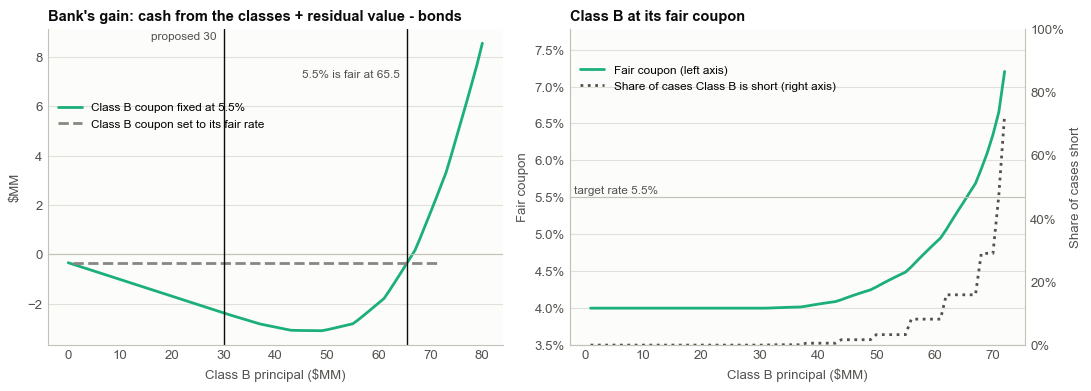

In [16]:
def plot_class_b_choice(at_target, fair_curve, target_coupon, break_even, proposed):
    """Bonus: the bank's gain against Class B's size (left); Class B's fair coupon and default probability (right)."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.0))
    shown = [row for row in at_target if row["b_notional"] <= 80]
    left.plot([row["b_notional"] for row in shown], [row["bank_gain"] for row in shown], color=COLORS["class_b"],
              label=f"Class B coupon fixed at {target_coupon:.1%}")
    left.plot([row["b_notional"] for row in fair_curve], [row["bank_gain"] for row in fair_curve],
              color=COLORS["benchmark"], linestyle="--", label="Class B coupon set to its fair rate")
    left.axhline(0, color=COLORS["axis"], linewidth=0.8)
    reference_line(left, proposed, f"proposed {proposed:.0f}", 0.99)
    reference_line(left, break_even, f"{target_coupon:.1%} is fair at {break_even:.1f}", 0.87)
    left.set_title("Bank's gain: cash from the classes + residual value - bonds")
    left.set_xlabel("Class B principal ($MM)")
    left.set_ylabel("$MM")
    left.legend(loc="upper left", bbox_to_anchor=(0.0, 0.8))

    fair_size = [row["b_notional"] for row in fair_curve]
    fair_rate = [row["fair_coupon"] for row in fair_curve]
    right.plot(fair_size, fair_rate, color=COLORS["class_b"], label="Fair coupon (left axis)")
    right.axhline(target_coupon, color=COLORS["axis"], linewidth=0.8)
    right.annotate(f"target rate {target_coupon:.1%}", xy=(0.01, target_coupon), xycoords=("axes fraction", "data"),
                   xytext=(0, 3), textcoords="offset points", fontsize=8.5, color=COLORS["ink_secondary"])
    right.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    right.set_ylim(0.035, max(fair_rate) * 1.08)
    right.set_ylabel("Fair coupon")
    short = right.twinx()
    short.plot(fair_size, [row["p_default_b"] for row in fair_curve], color=COLORS["ink_secondary"], linestyle=":",
               label="Share of cases Class B is short (right axis)")
    short.yaxis.set_major_formatter(PercentFormatter(1.0))
    short.set_ylim(0, 1)
    short.grid(False)
    short.spines["right"].set_visible(True)
    short.set_ylabel("Share of cases short")
    lines = right.get_legend_handles_labels(), short.get_legend_handles_labels()
    right.legend(lines[0][0] + lines[1][0], lines[0][1] + lines[1][1], loc="upper left", bbox_to_anchor=(0.0, 0.92))
    right.set_title("Class B at its fair coupon")
    right.set_xlabel("Class B principal ($MM)")
    fig.tight_layout()
    return fig


plot_class_b_choice(bonus["at_target_rate"], bonus["fair_coupon_curve"], base["b_coupon"], bonus["break_even_size"],
                    base["b_notional"])
plt.show()

Taken literally, the residual is worth the most with no Class B, because the three values always add up
to the bonds' market value. Measured by the bank's gain, Class B at its fair coupon gives the same result
at every size (the bank loses only what Class A's 4.5% costs). At the 5.5% target rate, 5.5% is a fair rate
for Class B at about $65.5 MM and the bank's gain only turns positive at about $66.5 MM, where Class B investors
would be paying more than the class is worth. Our structure keeps the sizes and pays both classes their fair
rate of 4.0%.